![Banner](../images/09_13_banner_rs_soil_moisture.png)

# ESA CCI: Long-Term Trends and Anomalies

The ESA Climate Change Initiative Soil Moisture (CCI SM) record merges every suitable passive and
active microwave sensor since 1978 into one daily dataset on a 0.25 degree grid. With more than 45
years it is long enough to ask climate questions: is the soil getting drier or wetter, and where?
This notebook reads the COMBINED product over Bangladesh from 1979 to 2024, shows how the record
changes as sensors come and go, builds monthly anomalies, and maps trends with the Mann-Kendall test
and Sen's slope for the whole year, the dry Rabi season and the monsoon.

## Overview

### Three products

| Product | Sensors | Units |
|---|---|---|
| PASSIVE | SMMR, SSM/I, TMI, AMSR-E, WindSat, AMSR2, SMOS, SMAP, GPM, FY-3 | m3 m-3 |
| ACTIVE | ERS-1, ERS-2 AMI-WS, ASCAT on MetOp-A, B and C | % saturation |
| COMBINED | both, merged | m3 m-3 |

### How the merging works

Each sensor's retrievals are rescaled to a common reference (GLDAS Noah land model soil moisture) by
CDF matching, so they share one climatology; where several sensors overlap, their values are
averaged with weights from triple collocation error estimates (Dorigo et al. 2017; Gruber et al.
2019), giving more weight to the sensor with the smaller error. Each value carries an uncertainty and
flags (frozen soil, dense vegetation, no convergence, water).

### Sensor eras and trends

The number and quality of sensors change over time: before 1987 only SMMR (every other day,
coarse), from 2002 AMSR-E, from 2007 ASCAT, from 2010 SMOS, from 2015 SMAP. Coverage and noise
change with them. Trends computed across sensor changes can be artefacts, so the analysis below
checks the data density through time and uses robust, rank-based statistics.

### Mann-Kendall and Sen's slope

The Mann-Kendall test asks whether later values tend to be larger (or smaller) than earlier ones,
using only the signs of all pairwise differences; it makes no assumption about the distribution.
Sen's slope is the median of all pairwise slopes, robust to outliers. Both are applied per cell to
annual (or seasonal) means.

## Long Records with GeoLattice

| Function | Purpose |
|---|---|
| `sd.cci("COMBINED", sd.BANGLADESH, ...)` (wraps `sm.open_product("ESA_CCI", ...)`) | daily cube from the CEDA THREDDS server |
| `sm.mask_quality` | CCI flags |
| `sm.sm_climatology`, `sm.sm_anomaly` | climatology and anomalies |
| `sm.trend` | Mann-Kendall test and Sen's slope per cell |

### Learning objectives

1. Read 46 years of merged satellite soil moisture for a country.
2. Recognize sensor eras in the data density and uncertainty.
3. Compute monthly anomalies and a national anomaly index.
4. Map per-cell trends and their significance, and compare seasons.

### Data

| Dataset | Content |
|---|---|
| ESA CCI SM v09.2 COMBINED, 1979 to 2024 | daily soil moisture, uncertainty and flags at 0.25 degree, 88 E to 92.7 E, 20.5 N to 26.7 N |
| geoBoundaries ADM0, Bangladesh | country outline |

### Contents

- Setup
- Data density and sensor eras
- Climatology and the monsoon cycle
- A national anomaly index
- Trends per cell
- Dry season and monsoon trends
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

import geopandas as gpd  # boundaries
from rasterio import features  # rasterize the outline
cci = sd.cci("COMBINED", sd.BANGLADESH, ("1979-01-01", "2024-12-31"), "bangladesh")  # 46 years of daily data
bgd = sd.boundaries("BGD", "ADM0")  # country outline
tmpl = cci.sm.isel(time=0, drop=True).rename({"lat": "y", "lon": "x"})  # grid template
inside = features.rasterize(bgd.geometry, out_shape=tmpl.shape, transform=tmpl.rio.write_crs(4326).rio.transform(), all_touched=True)  # cells of Bangladesh
land = xr.DataArray(inside.astype(bool), coords={"lat": cci.lat, "lon": cci.lon}, dims=("lat", "lon"))  # mask
good = sm.mask_quality(cci, level="all").sm.where(land)  # drop frozen and water flags, inside the country
print(cci.sizes, f"| {int(land.sum())} cells in Bangladesh")  # dimensions

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


Frozen({'time': 16802, 'lat': 26, 'lon': 20}) | 266 cells in Bangladesh


## Data density and sensor eras

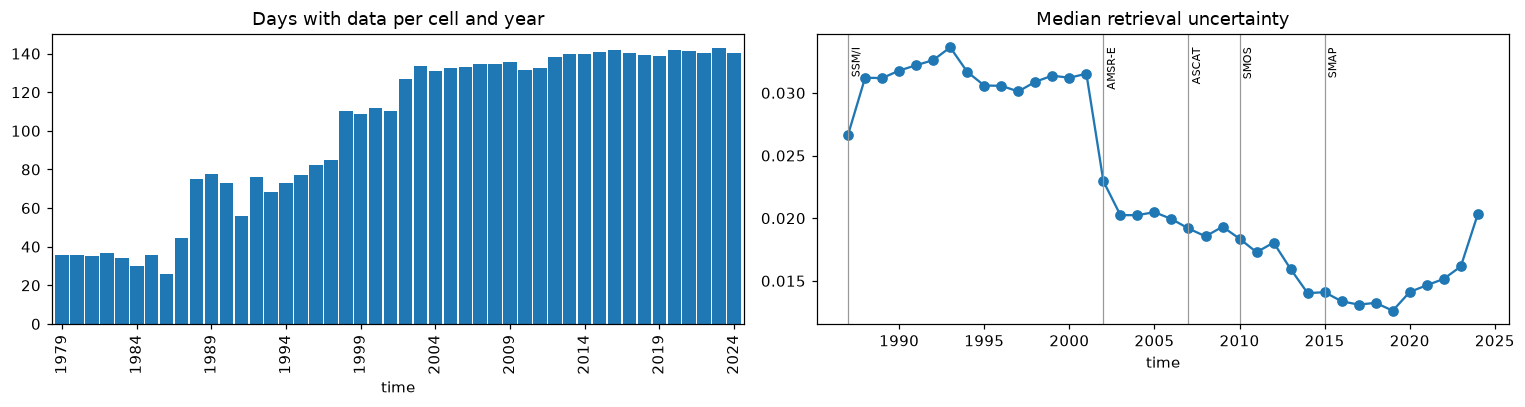

,days with data per cell,median uncertainty (m3/m3)
time,,
1980,35.510,NaN
1990,73.163,0.032
2000,111.767,0.031
2005,132.563,0.020
2010,131.654,0.018
2015,140.631,0.014
2020,141.702,0.014
2024,140.238,0.020


In [2]:
dens = good.notnull().mean(("lat", "lon")).to_series()  # share of cells with data per day
unc = cci.sm_uncertainty.where(land & good.notnull()).median(("lat", "lon")).to_series()  # median uncertainty per day
yearly = pd.DataFrame({"days with data per cell": dens.groupby(dens.index.year).sum(),
                       "median uncertainty (m3/m3)": unc.groupby(unc.index.year).median()})  # per year
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))  # two panels
yearly.iloc[:, 0].plot.bar(ax=ax[0], width=0.9, color="tab:blue"); ax[0].set_title("Days with data per cell and year")  # density
yearly.iloc[:, 1].plot(ax=ax[1], marker="o"); ax[1].set_title("Median retrieval uncertainty")  # uncertainty
for yr, lab in ((1987, "SSM/I"), (2002, "AMSR-E"), (2007, "ASCAT"), (2010, "SMOS"), (2015, "SMAP")):  # sensor arrivals
    ax[1].axvline(yr, color="0.6", lw=0.8); ax[1].text(yr + 0.2, ax[1].get_ylim()[1] * 0.97, lab, fontsize=7, rotation=90, va="top")  # markers
ax[0].set_xticks(ax[0].get_xticks()[::5]); plt.tight_layout(); plt.show()  # draw
display(yearly.loc[[1980, 1990, 2000, 2005, 2010, 2015, 2020, 2024]].round(3))  # selected years

Around 1980 a cell has a valid value on only about 35 days a year (SMMR observed every other day
and many retrievals are flagged); the density doubles in the SSM/I era and reaches about 140 days a
year after 2010. Even with many sensors, a large part of the year remains empty over Bangladesh because
of dense vegetation, open water and flags in the monsoon. The median uncertainty falls from about
0.032 m3 m-3 in 1990 to 0.014 in 2015 to 2020. Annual means of the early years therefore rest on far
fewer, noisier samples.

## Climatology and the monsoon cycle

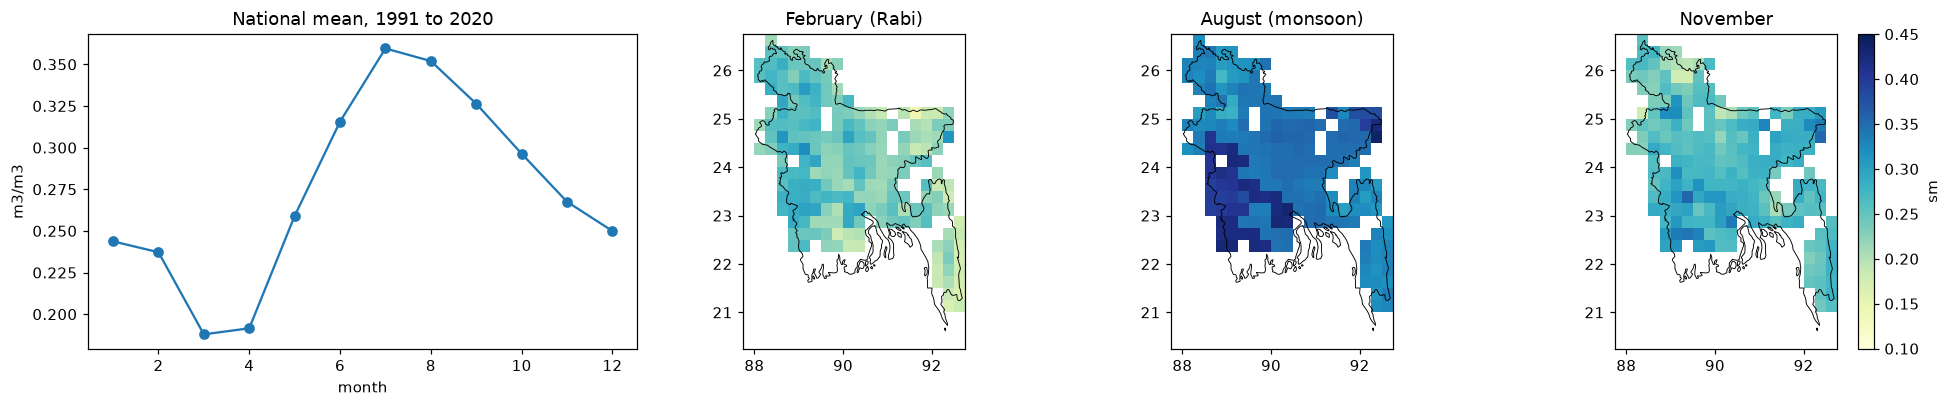

In [3]:
clim_m = good.sel(time=slice("1991", "2020")).groupby("time.month").mean()  # 1991 to 2020 monthly climatology
nat = clim_m.mean(("lat", "lon")).to_series()  # national mean
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})  # cycle and maps
nat.plot(ax=ax[0], marker="o"); ax[0].set_xlabel("month"); ax[0].set_ylabel("m3/m3"); ax[0].set_title("National mean, 1991 to 2020")  # cycle
for a, m, name in zip(ax[1:], (2, 8, 11), ("February (Rabi)", "August (monsoon)", "November")):  # three months
    clim_m.sel(month=m).plot(ax=a, vmin=0.1, vmax=0.45, cmap="YlGnBu", add_colorbar=a is ax[-1]); bgd.boundary.plot(ax=a, color="k", lw=0.6)  # map
    a.set_title(name); a.set_xlabel(""); a.set_ylabel("")  # title
plt.tight_layout(); plt.show()  # draw

The national mean falls from about 0.24 m3 m-3 in January to its minimum of about 0.19 in March and
April, at the end of the dry Rabi season (wheat, mustard and irrigated Boro rice), and peaks at about
0.36 in July with the monsoon. The February map shows the drier north-west (Rajshahi and Rangpur);
in August the western and southern plains are the wettest. Monsoon values are the least reliable, since
open water and flooded paddies fill many cells.

## A national anomaly index

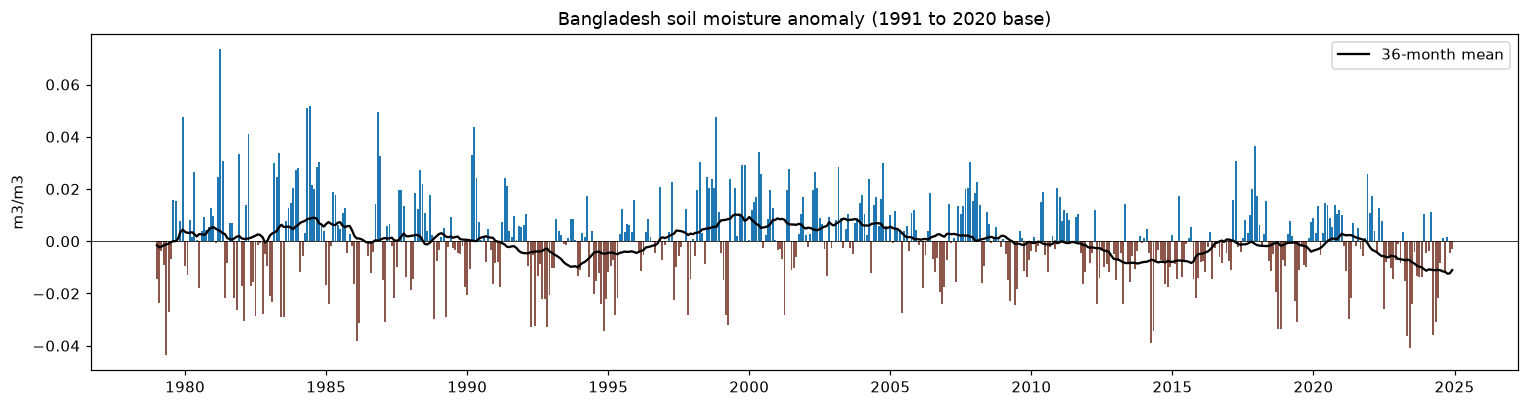

five driest months: {Timestamp('1979-05-01 00:00:00'): -0.0430000014603138, Timestamp('2023-06-01 00:00:00'): -0.04100000113248825, Timestamp('2014-04-01 00:00:00'): -0.039000000804662704, Timestamp('1986-02-01 00:00:00'): -0.03799999877810478, Timestamp('2023-05-01 00:00:00'): -0.035999998450279236}


In [4]:
mon = good.resample(time="MS").mean()  # monthly means per cell
cnt = good.notnull().resample(time="MS").sum()  # daily values per month
mon = mon.where(cnt >= 5)  # require five days per month
anom = mon.groupby("time.month") - mon.sel(time=slice("1991", "2020")).groupby("time.month").mean()  # monthly anomaly
idx = anom.mean(("lat", "lon")).to_series()  # national anomaly
fig, ax = plt.subplots(figsize=(14, 3.8))  # time series
ax.bar(idx.index, idx.values, width=25, color=np.where(idx > 0, "tab:blue", "tab:brown"))  # bars
ax.plot(idx.rolling(36, min_periods=12, center=True).mean(), "k", lw=1.5, label="36-month mean")  # smooth
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("m3/m3"); ax.legend(); ax.set_title("Bangladesh soil moisture anomaly (1991 to 2020 base)")  # labels
plt.tight_layout(); plt.show()  # draw
print("five driest months:", idx.nsmallest(5).round(3).to_dict())  # extremes

The driest months of the record include May 1979, April 2014 and the pre-monsoon of 2023 (May and
June), when the late arrival of the monsoon left the soils far below their usual level. The 36-month
mean shows multi-year swings (wet late 1990s, dry mid-2010s) and reaches its lowest value of the
whole record in 2023 and 2024.

## Trends per cell

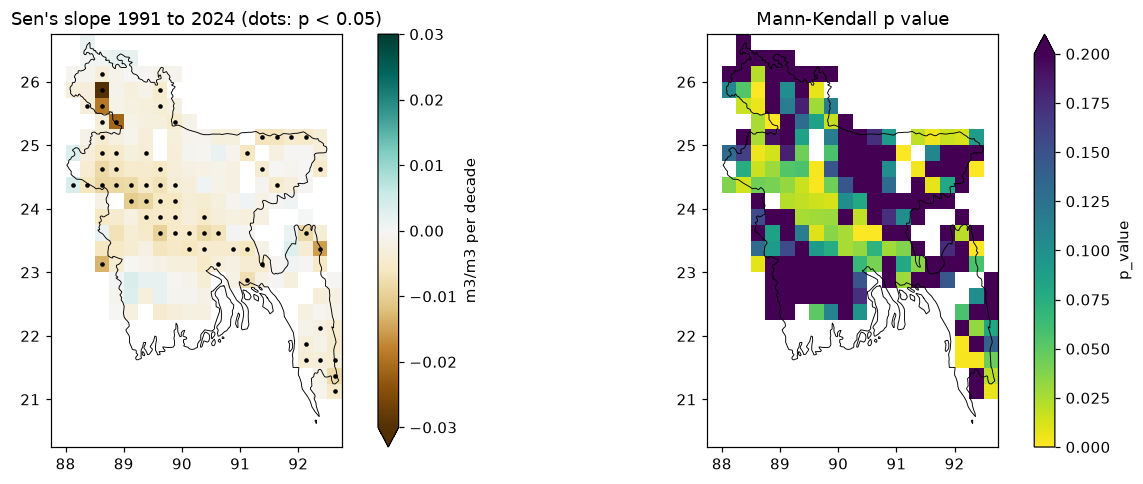

cells drying: 71%, significant drying 23%; significant wetting 0%; median -0.0029 m3/m3 per decade


In [5]:
recent = good.sel(time=slice("1991", "2024"))  # the period with SSM/I onwards
tr = sm.trend(recent, freq="YS", min_count=60)  # annual means with at least 60 days, Mann-Kendall and Sen
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))  # slope and significance
(tr.slope * 10).where(land).plot(ax=ax[0], cmap="BrBG", vmin=-0.03, vmax=0.03, cbar_kwargs={"label": "m3/m3 per decade"})  # Sen slope
yy, xx = np.meshgrid(tr.lat, tr.lon, indexing="ij"); sig = (tr.significant & land).values.astype(bool)  # significant cells
ax[0].scatter(xx[sig], yy[sig], s=4, c="k"); ax[0].set_title("Sen's slope 1991 to 2024 (dots: p < 0.05)")  # stippling
tr.p_value.where(land).plot(ax=ax[1], cmap="viridis_r", vmin=0, vmax=0.2); ax[1].set_title("Mann-Kendall p value")  # p values
for a in ax: bgd.boundary.plot(ax=a, color="k", lw=0.6); a.set_xlabel(""); a.set_ylabel("")  # outline
plt.tight_layout(); plt.show()  # draw
s = (tr.slope * 10).where(land)  # per decade
print(f"cells drying: {float((s < 0).sum() / land.sum()):.0%}, significant drying {float(((s < 0) & tr.significant).sum() / land.sum()):.0%}; "
      f"significant wetting {float(((s > 0) & tr.significant).sum() / land.sum()):.0%}; median {float(s.median()):+.4f} m3/m3 per decade")  # summary

## Dry season and monsoon trends

In [6]:
rows = {}  # national trend per season
for name, months in (("Rabi (Dec to Mar)", [12, 1, 2, 3]), ("pre-monsoon (Apr to May)", [4, 5]), ("monsoon (Jun to Sep)", [6, 7, 8, 9])):  # seasons
    sub = recent.where(recent.time.dt.month.isin(months))  # one season
    shifted = sub.assign_coords(time=sub.time.to_index() + pd.DateOffset(months=1)) if 12 in months else sub  # December counts with the next year
    ts = shifted.mean(("lat", "lon")).resample(time="YS").mean().to_series().dropna()  # national seasonal mean per year
    t_ = sm.trend(xr.DataArray(ts.values, coords={"time": ts.index}, dims="time"), freq="YS")  # trend of the national series
    rows[name] = {"years": len(ts), "Sen slope (m3/m3 per decade)": float(t_.slope) * 10, "p": float(t_.p_value)}  # result
display(pd.DataFrame(rows).T.round(4))  # table

,years,Sen slope (m3/m3 per decade),p
Rabi (Dec to Mar),35.0,0.0033,0.0381
pre-monsoon (Apr to May),34.0,-0.0063,0.0353
monsoon (Jun to Sep),34.0,-0.0045,0.0128


Since 1991, 71 % of the cells have a negative Sen's slope and 23 % a significant drying trend
(p < 0.05), concentrated in the west and north-west; no cell has a significant wetting trend. The
median slope is small, about -0.003 m3 m-3 per decade. By season the national series dries in the
pre-monsoon (-0.006 per decade) and monsoon (-0.005), while the dry Rabi season gets slightly wetter
(+0.003), all significant at 5 %. A wetter dry season while the rest of the year dries is what the
expansion of groundwater-irrigated Boro rice would produce. These trends are small against the
year-to-year variability and comparable with the steps that sensor changes can introduce, so a
significant trend in a merged record is a hypothesis to check against independent data (rain gauges,
reanalysis, groundwater), not a finding on its own.

## Summary and exercises

- ESA CCI COMBINED gives 46 years of daily soil moisture over Bangladesh; data density rises from
  about 35 to 140 valid days per cell and year, and uncertainty halves, as sensors are added.
- The national mean is lowest in March and April (about 0.19 m3 m-3) and highest in July (about 0.36).
- The national anomaly index ranks the pre-monsoon of 2023 among the driest months on record.
- Since 1991 a quarter of the cells dry significantly, mainly in the north-west, while the Rabi season
  gets slightly wetter; such trends must be weighed against sensor changes in the record.

**Exercises**

1. Recompute the trend map from 2007 to 2024 only (dense ASCAT and multi-sensor era). Are the
   significant cells the same?
2. Use `sm.mask_quality(cci, level="recommended")` (flag 0 only). How many monsoon values remain?
3. Compare the national anomaly index with the annual rainfall of a Bangladesh station from a public
   source, and compute their correlation.